# Practical Assignment 7: Brain Tumor Classification using CNN

**Aim:** Build a Convolutional Neural Network (CNN) to classify Brain MRI scans into 4 categories: Glioma Tumor, Meningioma Tumor, No Tumor, and Pituitary Tumor.

**Key Concepts to Remember:**
1. **Medical Imaging Multi-Class:** 4-class classification on brain MRI scans.
2. **Data Structure:** Training and Testing folders partitioned into 4 class directories.
3. **CNN Head:** Output layer has 4 softmax neurons corresponding to tumor classes.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
import numpy as np

# Step 1: Load Brain Tumor MRI Scans from Training and Testing directories
train_dir = r'd:/workspace01/4th year/DL/LabPracticesIV_DEEP_LEARNING/dataset/brain tumour/Training'
test_dir = r'd:/workspace01/4th year/DL/LabPracticesIV_DEEP_LEARNING/dataset/brain tumour/Testing'

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
).take(30)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
).take(10)

class_names = ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
print('Brain Tumor Classes:', class_names)

# Step 2: Build CNN Architecture
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Rescaling(1.0 / 255.0),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(4, activation='softmax')
])
model.summary()

# Step 3: Compile and Train Model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, epochs=3, validation_data=test_ds, verbose=1)

# Step 4: Evaluate and Predict
loss, acc = model.evaluate(test_ds, verbose=0)
print(f'\nBrain Tumor Test Accuracy: {acc*100:.2f}% | Test Loss: {loss:.4f}')

for images, labels in test_ds.take(1):
    preds = model.predict(images[:3], verbose=0)
    for i in range(3):
        pred_name = class_names[np.argmax(preds[i])]
        true_name = class_names[labels[i]]
        print(f'MRI Scan {i+1} -> Predicted: {pred_name:<18} | Actual: {true_name}')


Found 2870 files belonging to 4 classes.
Found 394 files belonging to 4 classes.
Brain Tumor Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
Model: "sequential_4"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼───

### Step 5: Plot Training & Validation Loss and Accuracy Curves

Visualizing loss and accuracy trajectories across training epochs confirms convergence and checks for overfitting.


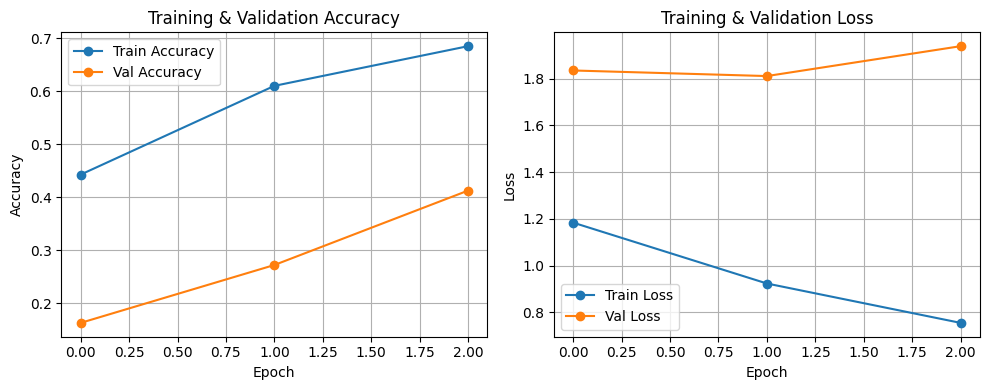

In [2]:
import matplotlib.pyplot as plt

# Step 5: Plot Training & Validation Accuracy and Loss Curves
plt.figure(figsize=(10, 4))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
